In MCNP, this is an example which a cylinder cell is created at the origin and translated to (0,10,15), then rotated. This is done with the TR card. OpenMC has an identical feature, but it is something that works on an OpenMC region first.

In [1]:
import openmc as omc

# Surface definitions. This is done in the (x',y',z') system. 
                                    # base of cylinder, height, radius
s1 = omc.model.RightCircularCylinder((0,-7,0),14,4,'y')
region = -s1 
print(type(region)) # yields a type of region 

<class 'openmc.region.Intersection'>


In [2]:
# rotate before translate so that you don't have to adjust the pivot point.

# two options to use rotate
# 1. pass a 3-tuple [rotation about x-axis, about y-axis, about z-axis] 
# 2. pass a full rotation matrix [3x3 iterable]

region = region.rotate([(0, 90, 90), (90, 30, 60), (90, 120, 30)])#,pivot =(0,0,0))
# when working with a rotation matrix, keep this in mind:
# the first 3-tuple is: (x->x', y->x', z->x').
# the second 3-tuple is:(x->y', y->y', z->z')
# the third 3-tuple is: (x->z', y->z', z->z')

# pass a vector that goes from the origin of the 
# global coordinate system to the origin of the x',y', z' auxiliary coord system
region=region.translate((0-0, 10-0, 15-0))


In [3]:
# Cell definitions
c1 = omc.Cell(fill=None,region=region)
#c2 = omc.Cell(cell_id=2,fill=None,region=~c1.region)
geometry = omc.Geometry([c1])
geometry.export_to_xml()

In [4]:
material=omc.Materials()
material.cross_sections='/home/jovibuca/endf/endfb-viii.0-hdf5/cross_sections.xml'
material.export_to_xml()

settings = omc.Settings()
settings.export_to_xml()

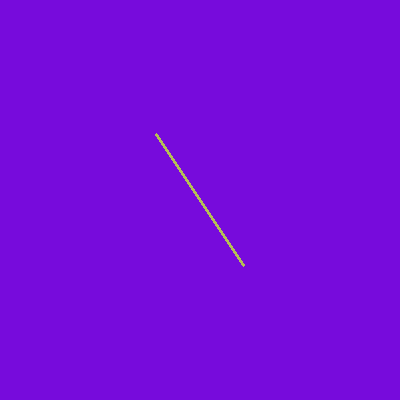

In [5]:
w = 5
plots = omc.Plots()

plot = omc.VoxelPlot()
plot.pixels=(100,100,100)
plot.origin = (0.0, 10.0, 15.0)#(0.0, 10.0, 15.0) 
plot.width = (w,w,w)
plot.color_by= 'cell'
plots.append(plot)

omc.plot_inline(plots)


Need to figure out if this is the intended outcome; no diagram is provided in the MCNP primer.